In [1]:
# 캘리포니아 주택 가격 예측 미니 프로젝트 : 회귀(값을 맞추는 문제, 주택 가격)

In [2]:
%matplotlib inline

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import koreanize_matplotlib

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [7]:
# 마이너스 기호 깨짐 방지 코드
plt.rcParams['axes.unicode_minus'] = False

In [8]:
df = pd.read_csv('housing.csv')
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [10]:
display( pd.DataFrame( {'자료형': df.dtypes, '결측치': df.isna().sum()} ) )

,자료형,결측치
longitude,float64,0
latitude,float64,0
housing_median_age,float64,0
total_rooms,float64,0
total_bedrooms,float64,207
population,float64,0
households,float64,0
median_income,float64,0
median_house_value,float64,0
ocean_proximity,object,0


In [11]:
print("중복 행:", df.duplicated().sum())

중복 행: 0


In [12]:
df = df.drop_duplicates() # 만약 중복 데이터가 있으면 삭제

In [13]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
print(f"학습 {len(train):,}행 / 테스트 {len(test):,}행")

학습 16,512행 / 테스트 4,128행


In [14]:
display(train.describe().round(2).T)

,count,mean,std,min,25%,50%,75%,max
longitude,16512.0,-119.57,2.00,-124.35,-121.78,-118.49,-118.01,-114.31
latitude,16512.0,35.63,2.13,32.54,33.94,34.25,37.72,41.95
housing_median_age,16512.0,28.59,12.62,1.00,18.00,29.00,37.00,52.00
total_rooms,16512.0,2635.52,2142.93,2.00,1454.75,2129.00,3152.25,32627.00
total_bedrooms,16349.0,538.92,418.20,1.00,296.00,437.00,648.00,6445.00
population,16512.0,1428.12,1134.04,3.00,788.00,1169.00,1726.00,35682.00
households,16512.0,500.26,379.27,1.00,280.00,411.00,606.00,6082.00
median_income,16512.0,3.86,1.91,0.50,2.56,3.52,4.73,15.00
median_house_value,16512.0,206111.15,114790.08,14999.00,119400.00,179200.00,263800.00,500001.00


In [15]:
display(train.groupby('ocean_proximity')['median_house_value'].agg(['count','mean','median']).round(0))

,count,mean,median
ocean_proximity,,,
<1H OCEAN,7313,239609.0,214800.0
INLAND,5276,124426.0,108800.0
ISLAND,5,380440.0,414700.0
NEAR BAY,1827,257631.0,232200.0
NEAR OCEAN,2091,249633.0,231300.0


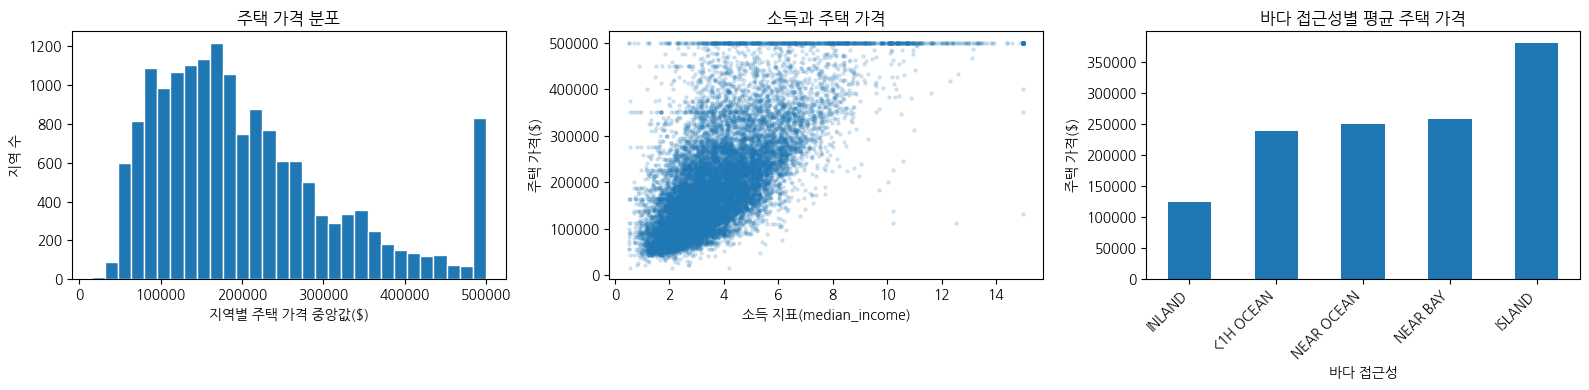

In [16]:
plt.figure(figsize=(16, 4))
plt.subplot(131)
plt.hist(train['median_house_value'], bins=30, edgecolor='white')
plt.title("주택 가격 분포")
plt.xlabel("지역별 주택 가격 중앙값($)")
plt.ylabel("지역 수")
plt.subplot(132)
plt.scatter(train['median_income'], train['median_house_value'], s=5, alpha=0.15)
plt.title('소득과 주택 가격')
plt.xlabel("소득 지표(median_income)")
plt.ylabel("주택 가격($)")
plt.subplot(133)
train.groupby('ocean_proximity')['median_house_value'].mean().sort_values().plot.bar()
plt.title("바다 접근성별 평균 주택 가격")
plt.xlabel("바다 접근성")
plt.ylabel("주택 가격($)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [17]:
corr = train.select_dtypes(include='number').corr()['median_house_value']
corr

longitude            -0.043603
latitude             -0.146324
housing_median_age    0.104714
total_rooms           0.134060
total_bedrooms        0.049993
population           -0.025820
households            0.065798
median_income         0.687013
median_house_value    1.000000
Name: median_house_value, dtype: float64

In [18]:
display( corr.drop('median_house_value').sort_values(ascending=False).round(3).to_frame('주택 가격과의 상관계수') )

,주택 가격과의 상관계수
median_income,0.687
total_rooms,0.134
housing_median_age,0.105
households,0.066
total_bedrooms,0.050
population,-0.026
longitude,-0.044
latitude,-0.146


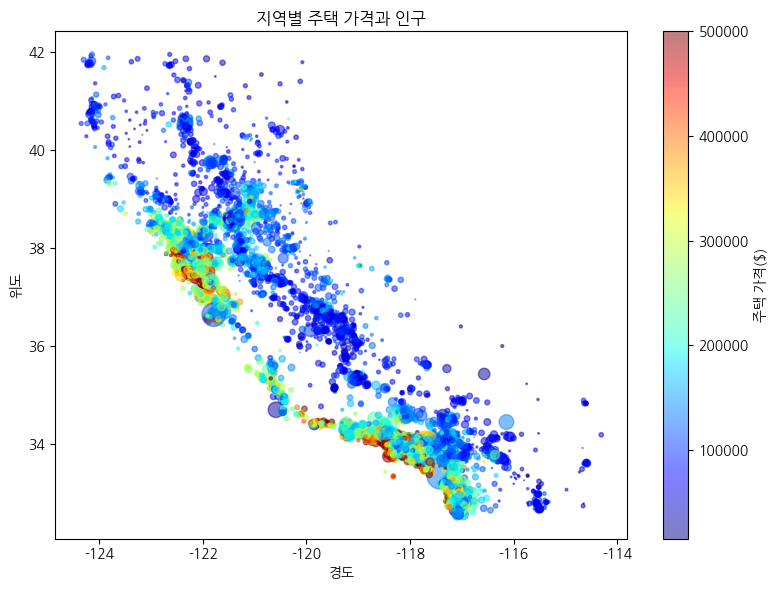

In [19]:
plt.figure(figsize=(8,6))
points = plt.scatter(
    train['longitude'], train['latitude'],
    s=train['population'] / 100,
    c=train['median_house_value'],
    cmap='jet', alpha=0.5
)
plt.colorbar(points, label='주택 가격($)')
plt.title("지역별 주택 가격과 인구")
plt.xlabel("경도")
plt.ylabel("위도")
plt.tight_layout()
plt.show()

In [20]:
target = 'median_house_value' # 정답 y컬럼
X_train, y_train = train.drop(columns=target), train[target]
X_test, y_test = test.drop(columns=target), test[target]

In [21]:
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

In [22]:
print("수치형:", num_cols)
print("범주형:", cat_cols)

수치형: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
범주형: ['ocean_proximity']


In [23]:
num_pipe = Pipeline([
    ( 'imputer', SimpleImputer(strategy='median') ),
    ( 'scaler', StandardScaler() )
])
cat_pipe = Pipeline([
    ( 'imputer', SimpleImputer(strategy='most_frequent') ),
    ( 'encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False) )
])
preprocess = ColumnTransformer([
    ( 'num', num_pipe, num_cols ),
    ( 'cat', cat_pipe, cat_cols )
])

In [24]:
models = {
    'LinearRegression' : Pipeline([
        ( 'prep', preprocess ), ( 'model', LinearRegression() )
    ]),
    'RandomForest' : Pipeline([
        ( 'prep', preprocess ), ( 'model', RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42) )
    ])
}

In [25]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv,
                            scoring='neg_root_mean_squared_error', n_jobs=-1)
    rows.append({'모델':name, "CV_RMSE":-scores.mean()}) # 낮을수록 좋다
comparison = pd.DataFrame(rows).set_index('모델')
display( comparison.round(0) )

,CV_RMSE
모델,
LinearRegression,68678.0
RandomForest,54289.0


In [26]:
%%time
# 튜닝
# model__ : Pipeline 안에서 model 단계의 설정을 바꾼다는 뜻, model__max_depth 는 max_depth 적용
params = {
    'model__max_depth': [ 10, None ],
    'model__min_samples_leaf': [ 1, 4 ]
}
search = GridSearchCV(models['RandomForest'], params, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
search.fit(X_train, y_train)
print("최적 설정:", search.best_params_)
# {'model__max_depth': None, 'model__min_samples_leaf': 1}
# RandomForestRegressor(max_depth=None, min_samples_leaf=1)
# Wall time: 13.5 s

최적 설정: {'model__max_depth': None, 'model__min_samples_leaf': 1}
CPU times: total: 7.25 s
Wall time: 14.5 s


In [27]:
search.cv_results_

{'mean_fit_time': array([3.6915582 , 3.6197292 , 6.49377831, 5.08461682]),
 'std_fit_time': array([0.05907501, 0.01736051, 0.10574627, 0.08925767]),
 'mean_score_time': array([0.04268893, 0.04330675, 0.09583505, 0.06663966]),
 'std_score_time': array([0.00189554, 0.00186206, 0.00065277, 0.00299024]),
 'param_model__max_depth': masked_array(data=[10, 10, None, None],
              mask=[False, False, False, False],
        fill_value='?',
             dtype=object),
 'param_model__min_samples_leaf': masked_array(data=[1, 4, 1, 4],
              mask=[False, False, False, False],
        fill_value='?',
             dtype=object),
 'params': [{'model__max_depth': 10, 'model__min_samples_leaf': 1},
  {'model__max_depth': 10, 'model__min_samples_leaf': 4},
  {'model__max_depth': None, 'model__min_samples_leaf': 1},
  {'model__max_depth': None, 'model__min_samples_leaf': 4}],
 'split0_test_score': array([-53133.10038083, -52937.57447561, -49319.95166712, -49616.85320078]),
 'split1_test_sco

In [28]:
tuning = pd.DataFrame(search.cv_results_)
tuning['CV_RMSE'] = -tuning['mean_test_score']
display( tuning[['param_model__max_depth', 'param_model__min_samples_leaf', 'CV_RMSE']].sort_values('CV_RMSE').round(0) )

,param_model__max_depth,param_model__min_samples_leaf,CV_RMSE
2,None,1,50423.0
3,None,4,50616.0
1,10,4,54014.0
0,10,1,54289.0


In [29]:
models['RandomForest tuned'] = search.best_estimator_
comparison.loc[ 'RandomForest tuned', 'CV_RMSE' ] = -search.best_score_
display( comparison.sort_values('CV_RMSE').round(0) ) # 낮을수록 좋다 --> 오차가 적다.

,CV_RMSE
모델,
RandomForest tuned,50423.0
RandomForest,54289.0
LinearRegression,68678.0


In [30]:
best_name = comparison['CV_RMSE'].idxmin() # "RandomForest tuned"
best = models[best_name] # models[ "RandomForest tuned" ]
best.fit(X_train, y_train)  # 훈련
pred = best.predict(X_test) # 예측
print("선택한 모델:", best_name)

선택한 모델: RandomForest tuned


In [31]:
result = pd.DataFrame({
    "MAE ($)" : [ mean_absolute_error(y_test, pred) ],
    "RMSE ($)" : [ np.sqrt( mean_squared_error(y_test, pred) ) ],
    "R2" : [ r2_score(y_test, pred) ]
}, index=[ best_name ])
display( result.round(3) )

,MAE ($),RMSE ($),R2
RandomForest tuned,32233.97,49726.336,0.822


In [32]:
mean_pred = np.full( len(y_test), y_train.mean() ) # 단순 평균 예측
print(f"평균만 예측한 기준 RMSE: ${np.sqrt(mean_squared_error(y_test, mean_pred)):,.0f}")
print(f"선택 모델의 평가 RMSE: ${np.sqrt(mean_squared_error(y_test, pred)):,.0f}")

평균만 예측한 기준 RMSE: $117,798
선택 모델의 평가 RMSE: $49,726


In [33]:
prediction = pd.DataFrame({'실제 가격': y_test, '예측 가격': pred})
# df['추가할_컬럼'] = 계산식
prediction['오차'] = prediction['실제 가격'] - prediction['예측 가격']
display( prediction.head(10).round(0) )

,실제 가격,예측 가격,오차
20046,65600.0,86410.0,-20810.0
3024,353400.0,342092.0,11308.0
15663,466700.0,420428.0,46272.0
20484,500001.0,451489.0,48512.0
9814,286100.0,240136.0,45964.0
13311,238300.0,165436.0,72864.0
7113,150000.0,149610.0,390.0
7668,146400.0,190906.0,-44506.0
18246,138000.0,152678.0,-14678.0
5723,477800.0,476949.0,851.0


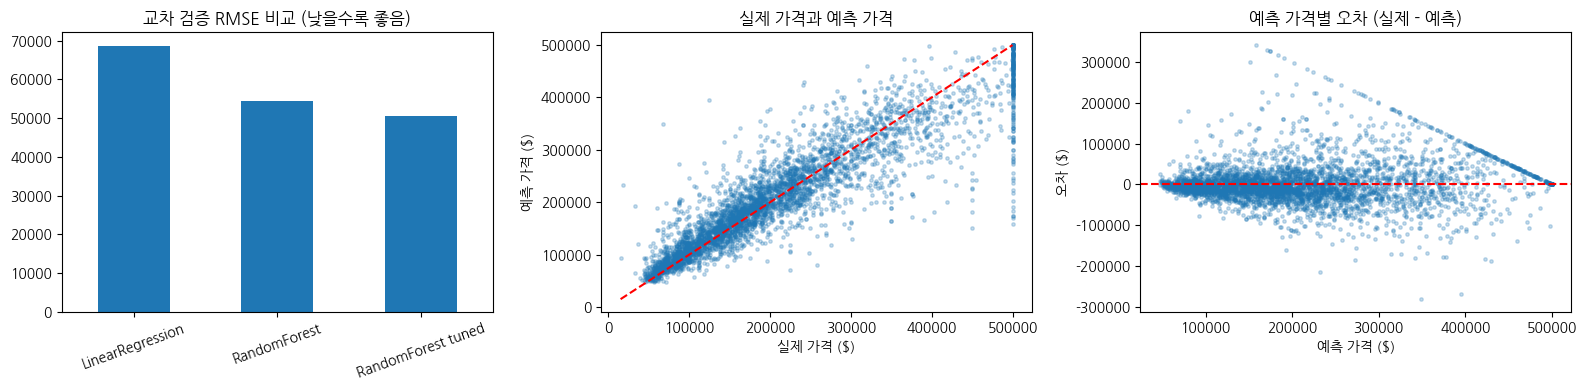

In [34]:
# 결과 시각화 : RMSE는 작을수록, 실제값과 예측값은 대각선에 가까울수록 좋음
plt.figure(figsize=(16,4))
plt.subplot(131)
comparison['CV_RMSE'].plot.bar(rot=20)
plt.title("교차 검증 RMSE 비교 (낮을수록 좋음)")
plt.xlabel("")
plt.subplot(132)
plt.scatter(y_test, pred, s=6, alpha=0.25)
limits = [ min(y_test.min(), pred.min()), max(y_test.max(), pred.max()) ]
plt.plot(limits, limits, 'r--')
plt.title("실제 가격과 예측 가격")
plt.xlabel("실제 가격 ($)")
plt.ylabel("예측 가격 ($)")
plt.subplot(133)
plt.scatter(pred, prediction['오차'], s=6, alpha=0.25)
plt.axhline(0, color='red', linestyle='--')
plt.title("예측 가격별 오차 (실제 - 예측)")
plt.xlabel("예측 가격 ($)")
plt.ylabel("오차 ($)")
plt.tight_layout()
plt.show()

In [35]:
# end